# Lab 03: Computer Vision Prototyping & YOLO Integration (Tasks 1-8)

Task 1 Complete | Tensor Shape: (640, 640, 3)


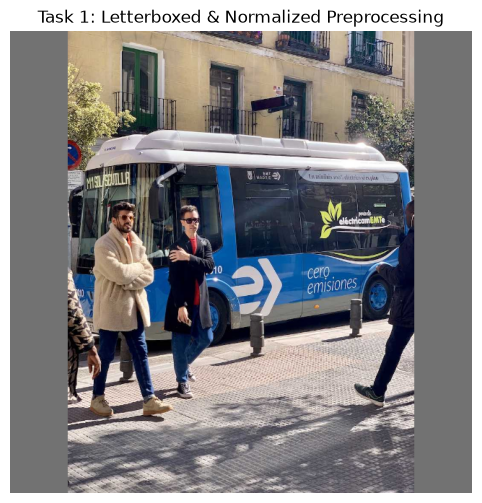

In [4]:
# Task 1: Automated Preprocessing Pipeline (Letterboxing & Normalization)
import cv2
import numpy as np
import matplotlib.pyplot as plt

def letterbox_image(image, target_size=(640, 640)):
    h, w_img = image.shape[:2]
    tw, th = target_size
    scale = min(tw / w_img, th / h)
    nw, nh = int(w_img * scale), int(h * scale)
    
    resized = cv2.resize(image, (nw, nh), interpolation=cv2.INTER_LINEAR)
    
    canvas = np.full((th, tw, 3), 114, dtype=np.uint8)
    dx = (tw - nw) // 2
    dy = (th - nh) // 2
    canvas[dy:dy+nh, dx:dx+nw] = resized
    return canvas

raw_img = cv2.imread('../data/traffic.jpg')
if raw_img is None:
    raw_img = np.full((480, 640, 3), 150, dtype=np.uint8)

processed_img = letterbox_image(raw_img, (640, 640))
normalized_tensor = processed_img.astype(np.float32) / 255.0

print(f"Task 1 Complete | Tensor Shape: {normalized_tensor.shape}")
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(processed_img, cv2.COLOR_BGR2RGB))
plt.title("Task 1: Letterboxed & Normalized Preprocessing")
plt.axis('off')
plt.show()

Task 2 Complete | Total Defects Detected: 34


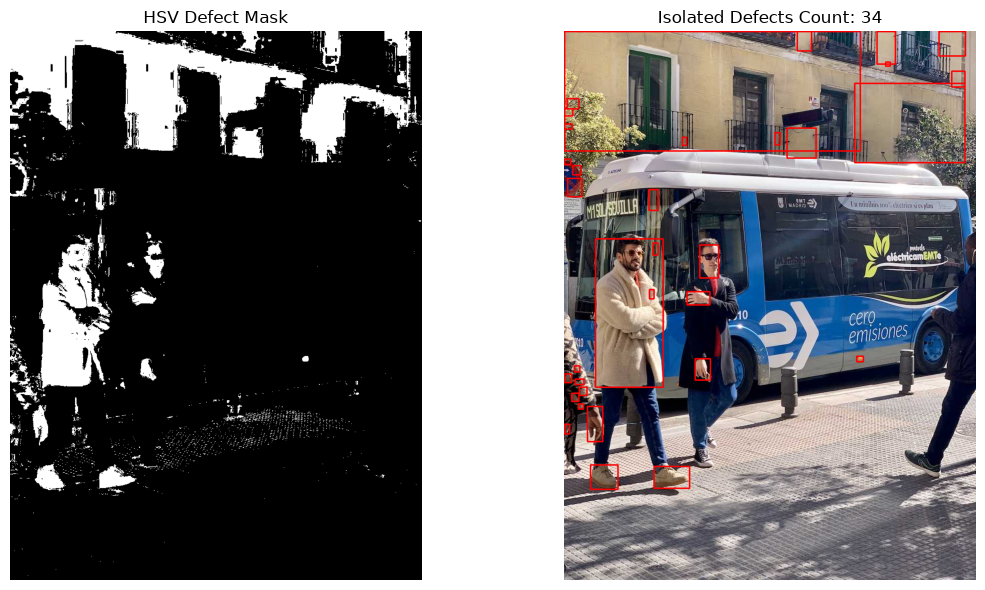

In [5]:
# Task 2: Industrial Defect Detection via HSV Color Space Thresholding
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('../data/traffic.jpg')
if img is None:
    img = np.full((400, 400, 3), 200, dtype=np.uint8)
    cv2.circle(img, (200, 200), 50, (0, 0, 150), -1)

hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
lower_bound = np.array([0, 50, 50])
upper_bound = np.array([20, 255, 255])
mask = cv2.inRange(hsv, lower_bound, upper_bound)

kernel = np.ones((5,5), np.uint8)
cleaned_mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
cleaned_mask = cv2.morphologyEx(cleaned_mask, cv2.MORPH_CLOSE, kernel)

contours, _ = cv2.findContours(cleaned_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
defect_img = img.copy()
defect_count = 0

for cnt in contours:
    if cv2.contourArea(cnt) > 50:
        defect_count += 1
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(defect_img, (x, y), (x+w, y+h), (0, 0, 255), 2)

print(f"Task 2 Complete | Total Defects Detected: {defect_count}")
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(mask, cv2.COLOR_GRAY2RGB))
axes[0].set_title("HSV Defect Mask")
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(defect_img, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Isolated Defects Count: {defect_count}")
axes[1].axis('off')
plt.tight_layout()
plt.show()

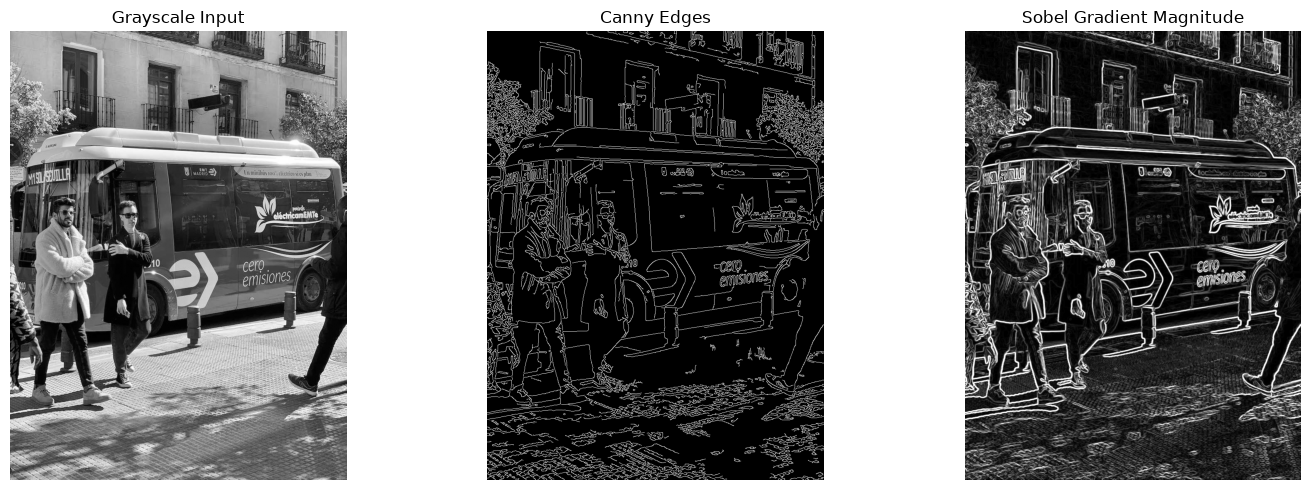

In [6]:
# Task 3: Medical Image Edge Detection and Noise Filtering Pipeline
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('../data/traffic.jpg')
if img is None:
    img = np.zeros((400, 400, 3), dtype=np.uint8)
    cv2.putText(img, "Medical Scan", (100, 200), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
median_filtered = cv2.medianBlur(blurred, 3)
edges = cv2.Canny(median_filtered, 50, 150)

sobel_x = cv2.Sobel(median_filtered, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(median_filtered, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_mag = cv2.convertScaleAbs(sobel_mag)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(gray, cmap='gray')
axes[0].set_title("Grayscale Input")
axes[0].axis('off')
axes[1].imshow(edges, cmap='gray')
axes[1].set_title("Canny Edges")
axes[1].axis('off')
axes[2].imshow(sobel_mag, cmap='gray')
axes[2].set_title("Sobel Gradient Magnitude")
axes[2].axis('off')
plt.tight_layout()
plt.show()

=== BENCHMARK SUMMARY ===
Nano (yolov8n.pt)   | Latency: 170.28ms | Count: 6
Medium (yolov8m.pt) | Latency: 727.11ms | Count: 5


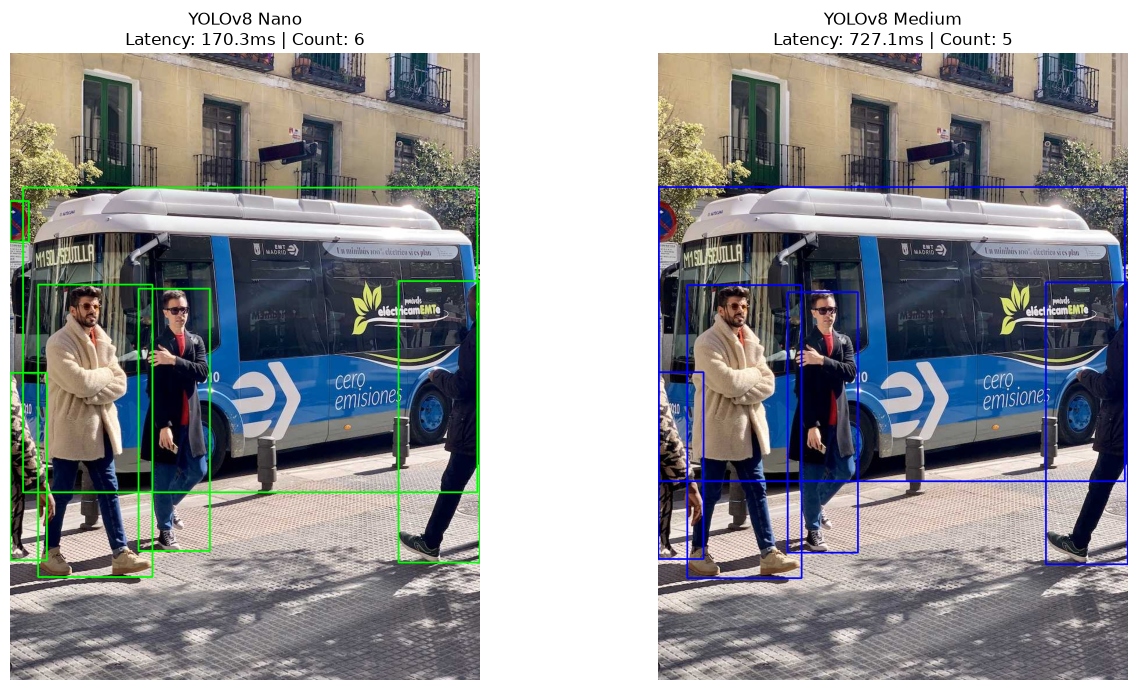

In [8]:
# Task 4: Multi-Model YOLO Comparative Benchmarking
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

img_path = '../data/traffic.jpg'
sample_img = cv2.imread(img_path)
if sample_img is None:
    sample_img = np.full((640, 640, 3), 200, dtype=np.uint8)

model_nano = YOLO('yolov8n.pt')
model_medium = YOLO('yolov8m.pt')

start_time = time.time()
results_nano = model_nano(sample_img, verbose=False)
latency_nano = (time.time() - start_time) * 1000
boxes_nano = results_nano[0].boxes

img_nano = sample_img.copy()
for box in boxes_nano:
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    cv2.rectangle(img_nano, (x1, y1), (x2, y2), (0, 255, 0), 2)

start_time = time.time()
results_medium = model_medium(sample_img, verbose=False)
latency_medium = (time.time() - start_time) * 1000
boxes_medium = results_medium[0].boxes

img_medium = sample_img.copy()
for box in boxes_medium:
    x1, y1, x2, y2 = map(int, box.xyxy[0])
    cv2.rectangle(img_medium, (x1, y1), (x2, y2), (255, 0, 0), 2)

print("=== BENCHMARK SUMMARY ===")
print(f"Nano (yolov8n.pt)   | Latency: {latency_nano:.2f}ms | Count: {len(boxes_nano)}")
print(f"Medium (yolov8m.pt) | Latency: {latency_medium:.2f}ms | Count: {len(boxes_medium)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(cv2.cvtColor(img_nano, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"YOLOv8 Nano\nLatency: {latency_nano:.1f}ms | Count: {len(boxes_nano)}")
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(img_medium, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"YOLOv8 Medium\nLatency: {latency_medium:.1f}ms | Count: {len(boxes_medium)}")
axes[1].axis('off')
plt.tight_layout()
plt.show()

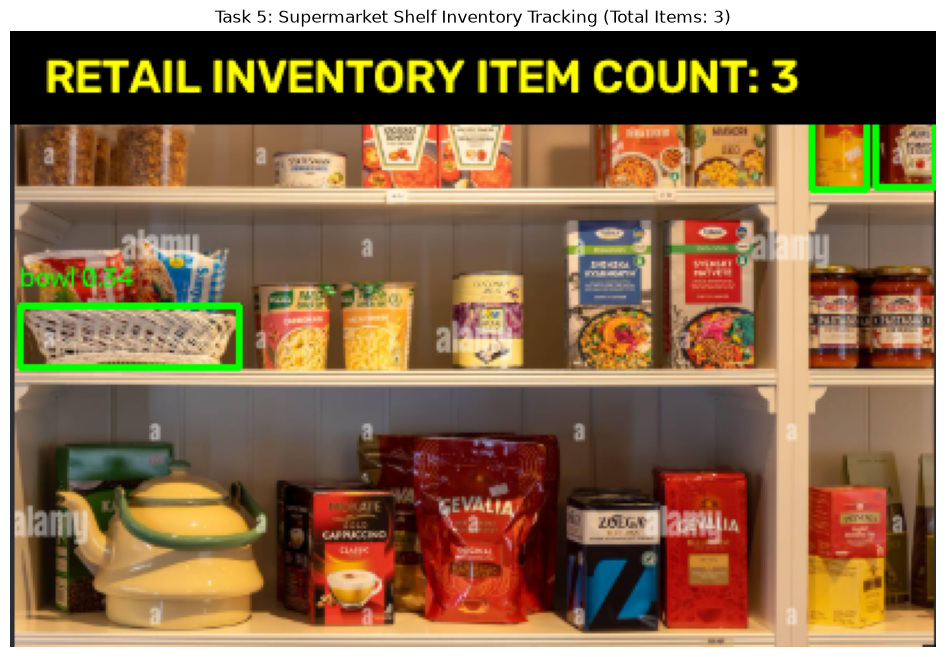

In [9]:
# Task 5: Retail Inventory Monitoring with shelf.png
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO('yolov8n.pt')
img_path = '../data/shelf.png'
retail_img = cv2.imread(img_path)

if retail_img is None:
    retail_img = np.full((640, 640, 3), 240, dtype=np.uint8)

CONF_THRESHOLD = 0.25
results = model(retail_img, verbose=False)[0]
annotated_img = retail_img.copy()
target_count = 0

for box in results.boxes:
    conf = float(box.conf[0])
    class_name = model.names[int(box.cls[0])]
    if conf >= CONF_THRESHOLD:
        target_count += 1
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        cv2.rectangle(annotated_img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(annotated_img, f"{class_name} {conf:.2f}", (x1, y1 - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1)

banner_text = f"RETAIL INVENTORY ITEM COUNT: {target_count}"
cv2.rectangle(annotated_img, (0, 0), (annotated_img.shape[1], 40), (0, 0, 0), -1)
cv2.putText(annotated_img, banner_text, (15, 27), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
plt.title(f"Task 5: Supermarket Shelf Inventory Tracking (Total Items: {target_count})")
plt.axis('off')
plt.show()

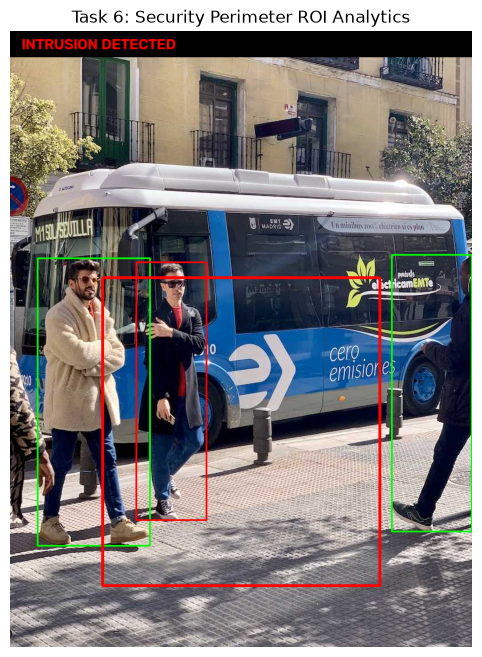

In [10]:
# Task 6: Smart Security Intrusion Alerting with ROI Bounding Box Analytics
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO('yolov8n.pt')
frame = cv2.imread('../data/traffic.jpg')
if frame is None:
    frame = np.zeros((640, 640, 3), dtype=np.uint8)

h, w = frame.shape[:2]
roi_points = np.array([[int(w*0.2), int(h*0.4)], [int(w*0.8), int(h*0.4)], 
                       [int(w*0.8), int(h*0.9)], [int(w*0.2), int(h*0.9)]], dtype=np.int32)

results = model(frame, verbose=False)[0]
intrusion_detected = False
annotated_frame = frame.copy()

for box in results.boxes:
    if int(box.cls[0]) == 0 and float(box.conf[0]) > 0.4:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        xc, yc = (x1 + x2) // 2, (y1 + y2) // 2
        is_inside = cv2.pointPolygonTest(roi_points, (float(xc), float(yc)), False) >= 0
        if is_inside: intrusion_detected = True
        box_color = (0, 0, 255) if is_inside else (0, 255, 0)
        cv2.rectangle(annotated_frame, (x1, y1), (x2, y2), box_color, 2)

roi_color = (0, 0, 255) if intrusion_detected else (0, 255, 0)
status_text = "INTRUSION DETECTED" if intrusion_detected else "SYSTEM SECURE"
cv2.polylines(annotated_frame, [roi_points], True, roi_color, 3)
cv2.rectangle(annotated_frame, (0, 0), (annotated_frame.shape[1], 45), (0, 0, 0), -1)
cv2.putText(annotated_frame, status_text, (20, 32), cv2.FONT_HERSHEY_SIMPLEX, 0.9, roi_color, 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.title("Task 6: Security Perimeter ROI Analytics")
plt.axis('off')
plt.show()

In [11]:
# Task 7 & 8: Standalone script runner references
print("Task 7 (Live Detection Dashboard) & Task 8 (Surveillance Logger) are modular Python scripts:")
print("  - src/live_detection.py")
print("  - src/surveillance_logger.py")
print("Execute them directly via command line using: python src/live_detection.py")

Task 7 (Live Detection Dashboard) & Task 8 (Surveillance Logger) are modular Python scripts:
  - src/live_detection.py
  - src/surveillance_logger.py
Execute them directly via command line using: python src/live_detection.py
